# Search or Think? Interim prototype (inference only, no RL yet)

It Builds a BM25 Wikipedia search tool, a multi turn search agent, the four reward functions (plain, fixed penalty, SAAS, Soft-SAAS) with unit tests, and the interim results: BM25 recall, p(q) distribution (go / no-go), no RL baselines, over search rates (QOR, SOR), and how often SAAS vs Soft-SAAS can give a search signal.

## 1. Install vLLM


In [ ]:
!pip install -q vllm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.3.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 whic

## 2. Config, Drive, GPU check


In [ ]:
PROJECT = "/content/drive/MyDrive/search_or_think"
SAVE_INDEX_TO_DRIVE = True
QUICK_N, FULL_N = 20, 500   # questions per dataset for the smoke test and the full runs

import os, sys
from google.colab import drive
drive.mount("/content/drive")
for d in ["index", "data", "outputs/figures", "checkpoints", "code/sot"]:
    os.makedirs(f"{PROJECT}/{d}", exist_ok=True)
CODE, DATA, OUT = f"{PROJECT}/code", f"{PROJECT}/data", f"{PROJECT}/outputs"
sys.path.insert(0, CODE)
import vllm, torch
print("vllm", vllm.__version__, "| torch", torch.__version__, "| GPU", torch.cuda.get_device_name(0))

Mounted at /content/drive
vllm 0.34.0 | torch 2.14.0+cu130 | GPU Tesla T4


## 3. Project code


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/__init__.py
"""Search or Think? project package."""


Overwriting /content/drive/MyDrive/search_or_think/code/sot/__init__.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/scoring.py
"""Answer scoring (SQuAD / HotpotQA style EM and F1) and evidence matching."""
import collections
import re
import string
import unicodedata

_PUNCT = set(string.punctuation)


def normalize_answer(s):
    s = unicodedata.normalize("NFKC", s or "").lower()
    s = "".join(ch for ch in s if ch not in _PUNCT)
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())


def em(pred, golds):
    p = normalize_answer(pred)
    return float(any(p == normalize_answer(g) for g in golds))


def f1(pred, golds):
    p = normalize_answer(pred)
    best = 0.0
    for g in golds:
        g = normalize_answer(g)
        # HotpotQA official eval: yes/no answers only score on an exact match
        if p != g and ({p, g} & {"yes", "no", "noanswer"}):
            continue
        common = collections.Counter(p.split()) & collections.Counter(g.split())
        ns = sum(common.values())
        if ns:
            prec, rec = ns / len(p.split()), ns / len(g.split())
            best = max(best, 2 * prec * rec / (prec + rec))
    return best


def has_answer(text, golds):
    t = f" {normalize_answer(text)} "
    return any(f" {normalize_answer(g)} " in t for g in golds if normalize_answer(g))


def norm_title(t):
    return unicodedata.normalize("NFKC", t or "").strip().strip('"').lower()


Overwriting /content/drive/MyDrive/search_or_think/code/sot/scoring.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/rewards.py
"""Rewards: plain GRPO, fixed per search penalty, SAAS, and Soft-SAAS (Eq. 1 of the proposal).

All search penalties apply only to fully correct answers (F1 = 1), so the policy is never pushed to guess.
"""
from dataclasses import dataclass
from typing import Optional

MAX_SEARCHES = 4


NOSEARCH_MIN_P = 1.0  # NoSearch only if every search disabled rollout is correct


def is_correct(f1):
    return f1 >= 1.0 - 1e-9


@dataclass
class Boundary:
    p: float              # fraction of K search disabled rollouts that are correct
    n_min: Optional[int]  # fewest searches in any correct search enabled rollout (None if none correct)
    label: str            # SAAS label: NoSearch / NeedSearch / Undetermined


def estimate_boundary(disabled_correct, enabled_rollouts, nosearch_min_p=NOSEARCH_MIN_P):
    """disabled_correct: list[bool]; enabled_rollouts: list of (correct: bool, n_search: int)."""
    p = sum(disabled_correct) / len(disabled_correct) if disabled_correct else 0.0
    ns = [n for c, n in enabled_rollouts if c]
    n_min = min(ns) if ns else None
    if p >= nosearch_min_p:
        label = "NoSearch"
    elif p == 0 and n_min is not None:
        label = "NeedSearch"
    else:
        label = "Undetermined"
    return Boundary(p, n_min, label)


def penalty_saas(n_search, b):
    if b.label == "NoSearch":
        return float(n_search)
    if b.label == "NeedSearch":
        return float(max(0, n_search - b.n_min))
    return 0.0  # Undetermined questions get no search signal


def penalty_soft(n_search, b, max_searches=MAX_SEARCHES):
    n_min = max_searches if b.n_min is None else b.n_min
    return b.p * n_search + (1 - b.p) * max(0, n_search - n_min)


def reward_plain(f1, n_search):
    return f1


def reward_fixed(f1, n_search, lam):
    return f1 - lam * n_search


def reward_saas(f1, n_search, b, alpha, w=1.0):
    return f1 - (alpha * w * penalty_saas(n_search, b) if is_correct(f1) else 0.0)


def reward_soft_saas(f1, n_search, b, alpha, w=1.0, max_searches=MAX_SEARCHES):
    return f1 - (alpha * w * penalty_soft(n_search, b, max_searches) if is_correct(f1) else 0.0)


class WarmupTrigger:
    """Self triggered warm up: w(t) = 0 until the moving average of training reward improves by
    less than eps over `window` steps, then w rises linearly to 1 over `ramp` steps."""

    def __init__(self, window=20, eps=0.005, ramp=50, ma=10):
        self.window, self.eps, self.ramp, self.ma = window, eps, ramp, ma
        self.rewards, self.mas, self.trigger_step = [], [], None

    def update(self, reward_mean):
        self.rewards.append(reward_mean)
        recent = self.rewards[-self.ma:]
        self.mas.append(sum(recent) / len(recent))
        t = len(self.rewards) - 1
        if self.trigger_step is None and len(self.mas) > self.window + self.ma:
            if self.mas[-1] - self.mas[-1 - self.window] < self.eps:
                self.trigger_step = t
        return self.weight(t)

    def weight(self, t):
        if self.trigger_step is None:
            return 0.0
        return min(1.0, (t - self.trigger_step) / self.ramp)


Overwriting /content/drive/MyDrive/search_or_think/code/sot/rewards.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/agent.py
"""Prompts and the batched multi turn search agent loop (model and retriever passed in as callables)."""
import re

SEARCH_RE = re.compile(r"<search>(.*?)</search>", re.S)
ANSWER_RE = re.compile(r"<answer>((?:(?!<answer>).)*?)</answer>", re.S)  # innermost, if a prefill <answer> is repeated
LIMIT_MSG = "\n\n<info>\nSearch limit reached. Give your final answer now.\n</info>\n\n"

_ANSWER_FMT = ("give the final answer inside <answer> and </answer> using only a few words, "
               "for example <answer> Paris </answer>.")
_DIRECT_FMT = "Respond with only the final answer in a few words inside <answer> and </answer>, with no explanation."

_AGENT_EXAMPLE = ("Example:\nQuestion: What is the capital of the country where the Eiffel Tower is?\n"
                  "<think> I need to know which country the Eiffel Tower is in. </think>\n"
                  "<search> Eiffel Tower location </search>\n\n"
                  "<info>\nDoc 1 (Title: Eiffel Tower) The Eiffel Tower is a wrought-iron lattice tower in Paris, France.\n</info>\n\n"
                  "<think> The tower is in France, and the capital of France is Paris. </think>\n"
                  "<answer> Paris </answer>")


def agent_instruction(question, max_searches=4):
    return ("Answer the question below. Reason inside <think> and </think> every time you get new information. "
            "If you lack some knowledge, search Wikipedia by writing <search> your query </search>, and the top "
            "results will be returned between <info> and </info>. Never invent search results. You can search up to "
            f"{max_searches} times. When you are ready, {_ANSWER_FMT}\n\n{_AGENT_EXAMPLE}\n\nQuestion: {question}")


def closed_book_instruction(question):
    return f"Answer the question below from your own knowledge. {_DIRECT_FMT}\n\nQuestion: {question}"


def rag_instruction(question):
    return ("Answer the question below. Wikipedia search results are provided between <info> and </info>. "
            f"{_DIRECT_FMT}\n\nQuestion: {question}")


def format_info(passages):
    body = "\n".join(f"Doc {i + 1} (Title: {p.get('title', '')}) {p.get('text', '')}" for i, p in enumerate(passages))
    return f"\n\n<info>\n{body or 'No results.'}\n</info>\n\n"


def extract_answer(text, lenient=False):
    m = ANSWER_RE.findall(text)
    if m:
        return m[-1].strip()
    if not lenient:
        return None
    if "<answer>" in text:  # answer opened (e.g. by the prefill) but never closed: keep its first line
        return " ".join(text.rsplit("<answer>", 1)[1].strip().split("\n")[0].split()[:12])
    # fallback for small models that skip the tags: last line outside think/info blocks, capped at 12 words
    t = re.sub(r"<info>.*?</info>|<think>.*?</think>", " ", text, flags=re.S)
    t = re.sub(r"<[^>]+>", " ", t)
    lines = [ln.strip() for ln in t.splitlines() if ln.strip()]
    return " ".join(lines[-1].split()[:12]) if lines else ""


def run_agent(generate, retrieve, prompts, *, allow_search=True, max_searches=4, max_turn_tokens=512,
              temperature=0.0, prefill=None):
    """generate(prompts, stop, max_tokens, temperature) -> list[str]; outputs include the stop string.
    retrieve(queries) -> list[list[{title, text}]].
    prefill: optional list of {"text", "searches"} placed at the start of the assistant turn (forced RAG search).
    Returns one state dict per prompt with text, searches, answer, format_ok, n_search, stop_reason."""
    states = [{"prompt": p, "text": prefill[i]["text"] if prefill else "",
               "searches": list(prefill[i]["searches"]) if prefill else [],
               "done": False, "over_limit": 0, "stop_reason": None}
              for i, p in enumerate(prompts)]
    stop = ["</search>", "</answer>"] if allow_search else ["</answer>"]
    for _ in range(max_searches + 2 if allow_search else 1):
        active = [s for s in states if not s["done"]]
        if not active:
            break
        outs = generate([s["prompt"] + s["text"] for s in active], stop, max_turn_tokens, temperature)
        need, queries = [], []
        for s, out in zip(active, outs):
            s["text"] += out
            tail = out.rstrip()
            if tail.endswith("</answer>"):
                s["done"], s["stop_reason"] = True, "answer"
            elif allow_search and tail.endswith("</search>"):
                if len(s["searches"]) >= max_searches:
                    s["over_limit"] += 1
                    if s["over_limit"] >= 2:
                        s["done"], s["stop_reason"] = True, "search_limit"
                    else:
                        s["text"] += LIMIT_MSG
                else:
                    m = SEARCH_RE.findall(out)
                    need.append(s)
                    queries.append(m[-1].strip() if m else "")
            else:
                s["done"], s["stop_reason"] = True, "no_tag" if out else "too_long"
        if queries:
            for s, q, res in zip(need, queries, retrieve(queries)):
                s["searches"].append({"query": q, "passages": res})
                s["text"] += format_info(res)
    for s in states:
        if not s["done"]:
            s["stop_reason"] = "max_turns"
        s["answer"] = extract_answer(s["text"], lenient=True)
        s["format_ok"] = extract_answer(s["text"]) is not None
        s["n_search"] = len(s["searches"])
    return states


Overwriting /content/drive/MyDrive/search_or_think/code/sot/agent.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/retrieval.py
"""Client for the local BM25 retrieval server (retriever_server.py)."""
import requests


class Retriever:
    def __init__(self, url="http://127.0.0.1:8000", k=3, batch=200, timeout=900):
        self.url, self.k, self.batch, self.timeout = url, k, batch, timeout

    def health(self):
        return requests.get(f"{self.url}/health", timeout=10).json()

    def __call__(self, queries):
        out = []
        for i in range(0, len(queries), self.batch):
            r = requests.post(f"{self.url}/search", json={"queries": queries[i:i + self.batch], "k": self.k},
                              timeout=self.timeout)
            r.raise_for_status()
            out += r.json()["results"]
        return out


Overwriting /content/drive/MyDrive/search_or_think/code/sot/retrieval.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/sot/analysis.py
"""Metrics over saved runs: accuracy tables, p(q) distribution, QOR, SOR, and the SAAS vs Soft-SAAS signal check."""
import collections
import json
import math

from .rewards import estimate_boundary, penalty_saas, penalty_soft
from .scoring import has_answer, norm_title


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else math.nan


def by_dataset(rows):
    g = collections.defaultdict(list)
    for r in rows:
        g[r["dataset"]].append(r)
    return dict(sorted(g.items()))


def summarize(rows):
    return {ds: {"n": len(v), "em": mean(r["em"] for r in v), "f1": mean(r["f1"] for r in v),
                 "searches": mean(r["n_search"] for r in v), "format_ok": mean(r["format_ok"] for r in v)}
            for ds, v in by_dataset(rows).items()}


def p_by_id(closed_rows):
    d = collections.defaultdict(list)
    for r in closed_rows:
        d[r["id"]].append(r["em"] >= 1.0)
    return {k: sum(v) / len(v) for k, v in d.items()}


def p_distribution(pmap, recs):
    out = {}
    for ds, v in by_dataset(recs).items():
        ps = [pmap[r["id"]] for r in v if r["id"] in pmap]
        out[ds] = {"n": len(ps), "hist": dict(sorted(collections.Counter(round(p, 2) for p in ps).items())),
                   "p0": mean(p == 0 for p in ps), "mid": mean(0 < p < 1 for p in ps), "p1": mean(p == 1 for p in ps)}
    return out


def qor(agent_rows, pmap, thr=0.5):
    """Question level over search: share of questions the base model can answer without search
    (p(q) >= thr) on which the policy still searches."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        elig = [r for r in v if pmap.get(r["id"], 0.0) >= thr]
        out[ds] = {"eligible": len(elig), "qor": mean(r["n_search"] > 0 for r in elig)}
    return out


def _evidence_complete(rec, titles, text):
    if rec["dataset"] == "hotpotqa":
        gold = {norm_title(t) for t in rec.get("sup_titles", [])}
        return bool(gold) and gold <= titles
    return has_answer(text, rec["golds"])


def sor(agent_rows, recs_by_id):
    """Step level over search: share of searches issued after all gold evidence was already retrieved."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        over = total = 0
        for r in v:
            rec, titles, text = recs_by_id[r["id"]], set(), ""
            for s in r["searches"]:
                over += _evidence_complete(rec, titles, text)
                total += 1
                titles |= {norm_title(t) for t in s["titles"]}
                text += " " + " ".join(s["texts"])
        out[ds] = {"searches": total, "sor": over / total if total else math.nan}
    return out


def boundary_signal(closed_rows, sampled_agent_rows):
    """How many questions can each reward penalise at all, and how often correct searching rollouts get penalised."""
    disabled, enabled, ds_of = collections.defaultdict(list), collections.defaultdict(list), {}
    for r in closed_rows:
        disabled[r["id"]].append(r["em"] >= 1.0)
    for r in sampled_agent_rows:
        enabled[r["id"]].append((r["em"] >= 1.0, r["n_search"]))
        ds_of[r["id"]] = r["dataset"]
    out = collections.defaultdict(lambda: {"questions": 0, "labels": collections.Counter(), "signal_saas": 0,
                                           "signal_soft": 0, "correct_searching": 0, "pen_saas": [], "pen_soft": []})
    for qid, rolls in enabled.items():
        if qid not in disabled:
            continue
        b = estimate_boundary(disabled[qid], rolls)
        o = out[ds_of[qid]]
        o["questions"] += 1
        o["labels"][b.label] += 1
        o["signal_saas"] += b.label != "Undetermined"
        o["signal_soft"] += b.p > 0 or b.n_min is not None
        for correct, n in rolls:
            if correct and n > 0:
                o["correct_searching"] += 1
                o["pen_saas"].append(penalty_saas(n, b))
                o["pen_soft"].append(penalty_soft(n, b))
    return {ds: {"questions": o["questions"], "labels": dict(o["labels"]),
                 "signal_saas": o["signal_saas"] / max(o["questions"], 1),
                 "signal_soft": o["signal_soft"] / max(o["questions"], 1),
                 "correct_searching_rollouts": o["correct_searching"],
                 "penalised_saas": mean(p > 0 for p in o["pen_saas"]),
                 "penalised_soft": mean(p > 0 for p in o["pen_soft"]),
                 "mean_pen_saas": mean(o["pen_saas"]), "mean_pen_soft": mean(o["pen_soft"])}
            for ds, o in sorted(out.items())}


Overwriting /content/drive/MyDrive/search_or_think/code/sot/analysis.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/run_inference.py
"""Inference only experiments for one model (no RL). Writes one jsonl per task to outputs/<model>/.

Tasks
  closed_sampled  K search disabled samples (T=1.0) on probe + test  -> p(q)
  no_search       greedy, no retrieval, test                         -> baseline
  rag             one forced search with the question, greedy, test  -> baseline
  agent           prompted search agent, greedy, test                -> baseline + QOR / SOR
  agent_sampled   K prompted agent samples (T=1.0) on probe          -> N_min, SAAS labels, reward signal check
"""
import argparse
import json
import os
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from sot.agent import agent_instruction, closed_book_instruction, format_info, rag_instruction, run_agent
from sot.retrieval import Retriever
from sot.scoring import em, f1

ALL_TASKS = "closed_sampled,no_search,rag,agent,agent_sampled"


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def to_row(rec, s, sample):
    return {"id": rec["id"], "dataset": rec["dataset"], "split": rec["split"], "sample": sample,
            "answer": s["answer"], "format_ok": s["format_ok"], "em": em(s["answer"], rec["golds"]),
            "f1": f1(s["answer"], rec["golds"]), "n_search": s["n_search"], "stop_reason": s["stop_reason"],
            "searches": [{"query": x["query"], "titles": [p["title"] for p in x["passages"]],
                          "texts": [p["text"] for p in x["passages"]]} for x in s["searches"]],
            "text": s["text"]}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", required=True)
    ap.add_argument("--project", required=True)
    ap.add_argument("--n", type=int, default=500, help="questions per dataset per split")
    ap.add_argument("--k", type=int, default=4, help="samples per question for p(q) and N_min")
    ap.add_argument("--max_searches", type=int, default=4)
    ap.add_argument("--tasks", default=ALL_TASKS)
    ap.add_argument("--tag", default="")
    ap.add_argument("--max_model_len", type=int, default=8192)
    ap.add_argument("--gpu_mem", type=float, default=0.85)
    args = ap.parse_args()

    from vllm import LLM, SamplingParams

    data = os.path.join(args.project, "data")
    test = sum((load_jsonl(f"{data}/{d}_test.jsonl")[:args.n] for d in ("hotpotqa", "nq")), [])
    probe = sum((load_jsonl(f"{data}/{d}_probe.jsonl")[:args.n] for d in ("hotpotqa", "nq")), [])
    name = args.model.split("/")[-1] + (f"_{args.tag}" if args.tag else "")
    out_dir = os.path.join(args.project, "outputs", name)
    os.makedirs(out_dir, exist_ok=True)

    llm = LLM(model=args.model, dtype="bfloat16", gpu_memory_utilization=args.gpu_mem,
              max_model_len=args.max_model_len, seed=0, enable_prefix_caching=True)
    tok = llm.get_tokenizer()
    retrieve = Retriever(k=3)

    def chat(instr):
        return tok.apply_chat_template([{"role": "user", "content": instr}], tokenize=False, add_generation_prompt=True)

    def generate(prompts, stop, max_tokens, temperature):
        lens = [len(x) for x in tok(prompts, add_special_tokens=False)["input_ids"]]
        keep = [i for i, n in enumerate(lens) if n + max_tokens <= args.max_model_len]
        outs = [""] * len(prompts)
        if keep:
            sp = SamplingParams(temperature=temperature, top_p=1.0, max_tokens=max_tokens, stop=stop,
                                include_stop_str_in_output=True)
            for i, r in zip(keep, llm.generate([prompts[i] for i in keep], sp, use_tqdm=True)):
                outs[i] = r.outputs[0].text
        return outs

    def run(task, recs, instr_fn, k=1, temperature=0.0, allow_search=True, max_turn_tokens=512, rag=False,
            prefix=""):
        """prefix starts the assistant turn ("<answer>" or "<think>") so small models stay in the tag format."""
        t0 = time.time()
        recs_k = [r for r in recs for _ in range(k)]
        prefill = [{"text": prefix, "searches": []} for _ in recs_k]
        if rag:
            passages = retrieve([r["question"] for r in recs_k])
            prefill = [{"text": f"<search> {r['question']} </search>" + format_info(p) + prefix,
                        "searches": [{"query": r["question"], "passages": p}]} for r, p in zip(recs_k, passages)]
        states = run_agent(generate, retrieve, [chat(instr_fn(r["question"])) for r in recs_k],
                           allow_search=allow_search, max_searches=args.max_searches,
                           max_turn_tokens=max_turn_tokens, temperature=temperature, prefill=prefill)
        rows = [to_row(r, s, i % k) for i, (r, s) in enumerate(zip(recs_k, states))]
        with open(f"{out_dir}/{task}.jsonl", "w") as f:
            f.writelines(json.dumps(x) + "\n" for x in rows)
        mins = (time.time() - t0) / 60
        print(f"[{name}] {task}: {len(rows)} trajectories in {mins:.1f} min, "
              f"EM={sum(x['em'] for x in rows) / len(rows):.3f}, "
              f"searches={sum(x['n_search'] for x in rows) / len(rows):.2f}", flush=True)
        return mins

    agent_instr = lambda q: agent_instruction(q, args.max_searches)
    jobs = {
        "closed_sampled": lambda: run("closed_sampled", probe + test, closed_book_instruction, k=args.k,
                                      temperature=1.0, allow_search=False, max_turn_tokens=32, prefix="<answer>"),
        "no_search": lambda: run("no_search", test, closed_book_instruction, allow_search=False, max_turn_tokens=32,
                                 prefix="<answer>"),
        "rag": lambda: run("rag", test, rag_instruction, allow_search=False, max_turn_tokens=32, rag=True,
                           prefix="<answer>"),
        "agent": lambda: run("agent", test, agent_instr, prefix="<think>"),
        "agent_sampled": lambda: run("agent_sampled", probe, agent_instr, k=args.k, temperature=1.0, prefix="<think>"),
    }
    timings = {t: jobs[t]() for t in args.tasks.split(",")}
    with open(f"{out_dir}/timings.json", "w") as f:
        json.dump({"model": args.model, "n": args.n, "k": args.k, "minutes": timings}, f, indent=2)


if __name__ == "__main__":
    main()


Overwriting /content/drive/MyDrive/search_or_think/code/run_inference.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/retriever_server.py
"""BM25 retrieval server over a Pyserini Lucene index. Runs in its own venv (Java 21 + pyserini).

POST /search {"queries": [...], "k": 3} -> {"results": [[{docid, title, text, score}, ...], ...]}
"""
import json
import os
from typing import List

import uvicorn
from fastapi import FastAPI
from pydantic import BaseModel

os.environ.setdefault("OPENAI_API_KEY", "unused")  # pyserini builds an OpenAI client at import time; BM25 never calls it
from pyserini.search.lucene import LuceneSearcher
searcher = LuceneSearcher(os.environ["INDEX_DIR"])
THREADS = int(os.environ.get("THREADS", os.cpu_count() or 4))
app = FastAPI()


class SearchRequest(BaseModel):
    queries: List[str]
    k: int = 3


def parse_doc(docid):
    doc = searcher.doc(docid)
    contents = doc.raw() if doc is not None else ""
    try:
        contents = json.loads(contents).get("contents", contents)
    except (ValueError, AttributeError):
        pass
    title, sep, text = contents.partition("\n")  # DPR wiki passages are '"Title"\ntext'
    if not sep:
        title, text = "", contents
    return {"docid": docid, "title": title.strip().strip('"'), "text": text.strip()}


@app.get("/health")
def health():
    return {"ok": True, "num_docs": getattr(searcher, "num_docs", None)}


@app.post("/search")
async def search(req: SearchRequest):  # async: runs on the main thread that owns the JVM
    results = [[] for _ in req.queries]
    idx = [i for i, q in enumerate(req.queries) if q and q.strip()]
    if idx:
        hits = searcher.batch_search([req.queries[i].strip() for i in idx], [str(i) for i in idx],
                                     k=req.k, threads=THREADS)
        for i in idx:
            results[i] = [{**parse_doc(h.docid), "score": float(h.score)} for h in hits.get(str(i), [])]
    return {"results": results}


if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=int(os.environ.get("PORT", 8000)), log_level="warning")


Overwriting /content/drive/MyDrive/search_or_think/code/retriever_server.py


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/setup_retriever.sh
#!/usr/bin/env bash
# Sets up and starts the BM25 retrieval server on a fresh Colab VM.
# usage: bash setup_retriever.sh <project_dir> [save_index_to_drive: 1|0]
set -euo pipefail
PROJECT="$1"
SAVE_TO_DRIVE="${2:-1}"
INDEX_NAME="wikipedia-dpr-100w"
LOCAL_INDEX="/content/index/$INDEX_NAME"
TAR="$PROJECT/index/$INDEX_NAME.tar"
VENV=/content/retenv
LOG=/content/retriever.log

# 1. Java 21 (Pyserini/Anserini requirement)
if [ -d /usr/lib/jvm/java-21-openjdk-amd64 ]; then JH=/usr/lib/jvm/java-21-openjdk-amd64
elif [ -x /opt/jdk21/bin/java ]; then JH=/opt/jdk21
else
  echo "[setup] installing Java 21"
  if apt-get -qq update && apt-get -qq install -y openjdk-21-jdk-headless > /dev/null 2>&1; then
    JH=/usr/lib/jvm/java-21-openjdk-amd64
  else
    echo "[setup] apt failed, using Temurin 21"
    mkdir -p /opt/jdk21
    curl -sL "https://api.adoptium.net/v3/binary/latest/21/ga/linux/x64/jdk/hotspot/normal/eclipse" \
      | tar xz -C /opt/jdk21 --strip-components=1
    JH=/opt/jdk21
  fi
fi
export JAVA_HOME="$JH"
"$JAVA_HOME/bin/java" -version 2>&1 | head -1

# 2. Separate Python 3.11 venv for pyserini, so it never fights vLLM over torch versions
if [ ! -x "$VENV/bin/python" ]; then
  echo "[setup] building retriever venv"
  pip install -q uv
  uv venv -q --python 3.11 "$VENV"
  uv pip install -q --python "$VENV/bin/python" torch --index-url https://download.pytorch.org/whl/cpu
  uv pip install -q --python "$VENV/bin/python" pyserini fastapi uvicorn requests
fi

# 3. Index: restore from Drive if saved, else download once from Pyserini
if [ ! -d "$LOCAL_INDEX" ]; then
  mkdir -p /content/index
  if [ -f "$TAR" ]; then
    echo "[setup] restoring index from Drive"
    tar xf "$TAR" -C /content/index
  else
    echo "[setup] downloading prebuilt $INDEX_NAME index (one time, several GB)"
    "$VENV/bin/python" - "$INDEX_NAME" "$LOCAL_INDEX" <<'EOF'
import glob, os, shutil, sys
name, dest = sys.argv[1], sys.argv[2]
try:
    from pyserini.util import download_prebuilt_index
    path = download_prebuilt_index(name)
except Exception as e:
    print("download_prebuilt_index failed, falling back:", e)
    from pyserini.search.lucene import LuceneSearcher
    LuceneSearcher.from_prebuilt_index(name)
    path = sorted(glob.glob(os.path.expanduser(f"~/.cache/pyserini/indexes/*{name}*")))[-1]
shutil.move(path, dest)
print("index at", dest)
EOF
    if [ "$SAVE_TO_DRIVE" = "1" ]; then
      NEED=$(du -sb "$LOCAL_INDEX" | cut -f1)
      FREE=$(df -B1 --output=avail "$PROJECT" | tail -1)
      if [ "$FREE" -gt $((NEED + 2000000000)) ]; then
        echo "[setup] saving index tar to Drive (faster restore next session)"
        tar cf "$TAR" -C /content/index "$INDEX_NAME"
      else
        echo "[setup] not enough Drive space, skipping save (index will be re-downloaded next session)"
      fi
    fi
  fi
fi
du -sh "$LOCAL_INDEX"


if ! curl -s localhost:8000/health > /dev/null; then
  cd "$PROJECT/code"
  INDEX_DIR="$LOCAL_INDEX" setsid nohup "$VENV/bin/python" retriever_server.py > "$LOG" 2>&1 &
  for _ in $(seq 1 90); do
    curl -s localhost:8000/health > /dev/null && break
    sleep 2
  done
fi
curl -s localhost:8000/health || { echo "[setup] server failed, log:"; tail -50 "$LOG"; exit 1; }
echo


Overwriting /content/drive/MyDrive/search_or_think/code/setup_retriever.sh


In [ ]:
%%writefile /content/drive/MyDrive/search_or_think/code/test_sot.py
"""Unit tests: python -m pytest -q test_sot.py"""
import pytest

from sot.agent import extract_answer, run_agent
from sot.analysis import boundary_signal, p_by_id, qor, sor
from sot.rewards import (Boundary, WarmupTrigger, estimate_boundary, reward_fixed, reward_plain, reward_saas,
                         reward_soft_saas)
from sot.scoring import em, f1, has_answer

A = 0.1  # alpha


# scoring
def test_scoring():
    assert em("The Eiffel Tower!", ["eiffel tower"]) == 1.0
    assert f1("Paris France", ["Paris"]) == pytest.approx(2 / 3)
    assert f1("yes", ["no"]) == 0.0 and f1("no", ["no"]) == 1.0
    assert has_answer("Built in 1889 by Eiffel.", ["1889"]) and not has_answer("in 18890", ["1889"])


# rewards
def test_plain_and_fixed():
    assert reward_plain(0.7, 3) == 0.7
    assert reward_fixed(1.0, 2, 0.1) == pytest.approx(0.8)


def test_wrong_answers_never_penalised():
    for b in [Boundary(1.0, 0, "NoSearch"), Boundary(0.0, 1, "NeedSearch"), Boundary(0.5, 1, "Undetermined")]:
        assert reward_saas(0.5, 4, b, A) == 0.5
        assert reward_soft_saas(0.5, 4, b, A) == 0.5


def test_saas():
    assert reward_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A) == pytest.approx(0.8)
    assert reward_saas(1.0, 3, Boundary(0.0, 1, "NeedSearch"), A) == pytest.approx(0.8)
    assert reward_saas(1.0, 1, Boundary(0.0, 1, "NeedSearch"), A) == 1.0
    assert reward_saas(1.0, 4, Boundary(0.5, 1, "Undetermined"), A) == 1.0  # no signal


def test_soft_saas_matches_saas_at_extremes_and_mixes_between():
    assert reward_soft_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A) == pytest.approx(0.8)
    assert reward_soft_saas(1.0, 3, Boundary(0.0, 1, "NeedSearch"), A) == pytest.approx(0.8)
    # p = 0.5, N = 3, N_min = 1: 0.5*3 + 0.5*2 = 2.5 searches of penalty
    assert reward_soft_saas(1.0, 3, Boundary(0.5, 1, "Undetermined"), A) == pytest.approx(0.75)
    # never answerable and no correct searching rollout: only searches beyond the cap count
    assert reward_soft_saas(1.0, 4, Boundary(0.0, None, "Undetermined"), A) == 1.0
    assert reward_soft_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A, w=0.0) == 1.0  # warm up off


def test_estimate_boundary():
    assert estimate_boundary([True] * 4, [(True, 1)]).label == "NoSearch"
    b = estimate_boundary([False] * 4, [(False, 4), (True, 2), (True, 1)])
    assert (b.label, b.n_min, b.p) == ("NeedSearch", 1, 0.0)
    b = estimate_boundary([True, False, False, False], [(True, 2)])
    assert (b.label, b.p) == ("Undetermined", 0.25)
    assert estimate_boundary([False] * 4, [(False, 3)]).label == "Undetermined"


def test_warmup_trigger():
    w = WarmupTrigger(window=5, eps=0.01, ramp=10, ma=3)
    ws = [w.update(min(0.05 * t, 0.6)) for t in range(60)]  # rises for 12 steps, then flat
    assert w.trigger_step is not None and 12 < w.trigger_step < 30
    assert all(x == 0.0 for x in ws[:w.trigger_step + 1])
    assert ws[-1] == 1.0 and ws == sorted(ws)


# agent loop with a fake model and retriever
def fake_retrieve(queries):
    return [[{"title": f"T_{q}", "text": f"text about {q}"}] for q in queries]


def make_generate(script):
    """script: prompt keyword -> list of outputs, one per turn."""
    calls = {}

    def gen(prompts, stop, max_tokens, temperature):
        outs = []
        for p in prompts:
            key = next(k for k in script if k in p)
            turn = calls.get(p.split("|")[0], 0)
            calls[p.split("|")[0]] = turn + 1
            outs.append(script[key][turn] if turn < len(script[key]) else "")
        return outs
    return gen


def test_run_agent_paths():
    script = {
        "Q_direct": ["<think>know it</think><answer> Paris </answer>"],
        "Q_search": ["<think>?</think><search> eiffel </search>", "<think>ok</think><answer>1889</answer>"],
        "Q_greedy": ["<search> a </search>"] * 6 + ["<answer>x</answer>"],
        "Q_rambles": ["no tags here just text\nfinal guess Rome"],
    }
    prompts = [f"{k}|" for k in script]
    st = run_agent(make_generate(script), fake_retrieve, prompts, max_searches=2)
    d, s, g, r = st
    assert (d["answer"], d["n_search"], d["stop_reason"]) == ("Paris", 0, "answer")
    assert (s["answer"], s["n_search"]) == ("1889", 1) and "<info>" in s["text"] and "T_eiffel" in s["text"]
    assert g["n_search"] == 2 and g["stop_reason"] == "search_limit" and "Search limit reached" in g["text"]
    assert r["format_ok"] is False and r["answer"] == "final guess Rome" and r["stop_reason"] == "no_tag"


def test_closed_book_and_prefill():
    gen = make_generate({"Q": ["<think>x</think><answer>a</answer>"]})
    st = run_agent(gen, None, ["Q|"], allow_search=False,
                   prefill=[{"text": "<search> Q </search>", "searches": [{"query": "Q", "passages": []}]}])
    assert st[0]["answer"] == "a" and st[0]["n_search"] == 1
    assert extract_answer("<answer>a</answer> then <answer> b </answer>") == "b"
    assert extract_answer("<answer><answer> Paris </answer>") == "Paris"  # model repeats the prefilled tag
    assert extract_answer("<answer> Paris, France\nmore text", lenient=True) == "Paris, France"  # never closed
    assert extract_answer("<answer> Paris, France\nmore text") is None


# metrics
def test_metrics():
    recs = {"h1": {"dataset": "hotpotqa", "sup_titles": ["A", "B"], "golds": ["x"]},
            "n1": {"dataset": "nq", "sup_titles": [], "golds": ["1889"]}}
    agent = [
        {"id": "h1", "dataset": "hotpotqa", "n_search": 3, "searches": [
            {"titles": ["A"], "texts": [""]}, {"titles": ['"B"'], "texts": [""]}, {"titles": ["C"], "texts": [""]}]},
        {"id": "n1", "dataset": "nq", "n_search": 2, "searches": [
            {"titles": ["E"], "texts": ["built in 1889"]}, {"titles": ["E"], "texts": [""]}]},
    ]
    s = sor(agent, recs)
    assert s["hotpotqa"]["sor"] == pytest.approx(1 / 3) and s["nq"]["sor"] == pytest.approx(1 / 2)
    closed = [{"id": "h1", "dataset": "hotpotqa", "em": e} for e in (1, 1, 0, 0)] + \
             [{"id": "n1", "dataset": "nq", "em": 0}] * 4
    pm = p_by_id(closed)
    assert pm == {"h1": 0.5, "n1": 0.0}
    assert qor(agent, pm)["hotpotqa"]["qor"] == 1.0
    sampled = [{"id": "h1", "dataset": "hotpotqa", "em": 1, "n_search": 2},
               {"id": "n1", "dataset": "nq", "em": 1, "n_search": 3},
               {"id": "n1", "dataset": "nq", "em": 1, "n_search": 1}]
    sig = boundary_signal(closed, sampled)
    assert sig["hotpotqa"]["signal_saas"] == 0 and sig["hotpotqa"]["signal_soft"] == 1  # p = 0.5 only Soft sees it
    assert sig["nq"]["labels"] == {"NeedSearch": 1} and sig["nq"]["penalised_saas"] == 0.5


Overwriting /content/drive/MyDrive/search_or_think/code/test_sot.py


### Unit tests (rewards, scoring, agent loop, metrics)
All should pass before anything else runs.

In [ ]:
!cd {CODE} && python -m pytest -q test_sot.py

..........                                                               [100%]
10 passed in 2.22s


## 4. BM25 search tool


In [ ]:
!bash {CODE}/setup_retriever.sh {PROJECT} {int(SAVE_INDEX_TO_DRIVE)}

[0.020s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[setup] building retriever venv
[setup] restoring index from Drive
11G	/content/index/wikipedia-dpr-100w
{"ok":true,"num_docs":21015324}


In [ ]:
from sot.retrieval import Retriever
for p in Retriever(k=3)(["who designed the eiffel tower"])[0]:
    print(p["title"], "|", p["text"][:120])

Eiffel Tower replicas and derivatives | Ballroom, making it in itself one of the most unique replica-like Towers in the world. It was also designed by the Briti
Eiffel Tower | Eiffel Tower The Eiffel Tower ( ; ) is a wrought-iron lattice tower on the Champ de Mars in Paris, France. It is named a
Petřín Lookout Tower | of the Eiffel Tower. In contrast to the Eiffel Tower, Petřínská rozhledna has an octagonal, not square, cross-section. F


## 5. Data and retrieval check
Samples 1,000 questions per file (HotpotQA and NQ; dev sets as test, train sets as the probe), then measures BM25 recall.

In [ ]:
import json
import random

from datasets import load_dataset


def first_ok(*loaders):
    err = None
    for load in loaders:
        try:
            return load()
        except Exception as e:  # dataset ids move around on the Hub; try the fallback id
            err = e
            print("falling back after:", repr(e)[:150])
    raise err


def hotpot(split):
    return first_ok(lambda: load_dataset("hotpotqa/hotpot_qa", "distractor", split=split),
                    lambda: load_dataset("hotpot_qa", "distractor", split=split, trust_remote_code=True))


def nq(split):
    return first_ok(lambda: load_dataset("google-research-datasets/nq_open", split=split),
                    lambda: load_dataset("nq_open", split=split))


N_SAVE = 1000  # saved per file; runs use the first --n of them
# test = official dev sets (standard for Search-R1 style work, the test sets have no public labels);
# probe = training questions, used for the p(q) go / no-go check and N_min
for name, loader in [("hotpotqa", hotpot), ("nq", nq)]:
    for split, out in [("validation", "test"), ("train", "probe")]:
        d = loader(split)
        rows = []
        for i in random.Random(42).sample(range(len(d)), N_SAVE):
            x = d[i]
            if name == "hotpotqa":
                rows.append({"id": x["id"], "dataset": name, "split": out, "question": x["question"],
                             "golds": [x["answer"]], "sup_titles": sorted(set(x["supporting_facts"]["title"])),
                             "type": x["type"], "level": x["level"]})
            else:
                rows.append({"id": f"nq_{split}_{i}", "dataset": name, "split": out, "question": x["question"],
                             "golds": list(x["answer"]), "sup_titles": []})
        with open(f"{DATA}/{name}_{out}.jsonl", "w") as f:
            f.writelines(json.dumps(r) + "\n" for r in rows)
        print(f"{name}_{out}: {len(rows)} questions, e.g. {rows[0]['question']!r} -> {rows[0]['golds']}")


In [ ]:
import json
import time

from sot.analysis import load_jsonl, mean
from sot.retrieval import Retriever
from sot.scoring import has_answer, norm_title

r10 = Retriever(k=10)
recall = {}
hp = load_jsonl(f"{DATA}/hotpotqa_test.jsonl")[:FULL_N]
t0 = time.time()
res = r10([x["question"] for x in hp])
recall["queries_per_sec"] = len(hp) / (time.time() - t0)
for k in (3, 10):
    found = [({norm_title(t) for t in x["sup_titles"]}, {norm_title(p["title"]) for p in rs[:k]}) for x, rs in zip(hp, res)]
    recall[f"hotpotqa_any_gold@{k}"] = mean(bool(g & got) for g, got in found)
    recall[f"hotpotqa_both_gold@{k}"] = mean(g <= got for g, got in found)
nq_recs = load_jsonl(f"{DATA}/nq_test.jsonl")[:FULL_N]
res = r10([x["question"] for x in nq_recs])
for k in (3, 10):
    recall[f"nq_answer_in_top{k}"] = mean(has_answer(" ".join(p["text"] for p in rs[:k]), x["golds"])
                                          for x, rs in zip(nq_recs, res))
json.dump(recall, open(f"{OUT}/bm25_recall.json", "w"), indent=2)
for k, v in recall.items():
    print(f"{k:24s} {v:.3f}")


## 6. Smoke test


In [ ]:
!cd {CODE} && python run_inference.py --model Qwen/Qwen2.5-0.5B-Instruct --project {PROJECT} --n {QUICK_N} --k 2 --tag quick

(MainProcess pid=4802) INFO 10-25 06:26:01 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'max_model_len': 8192, 'enable_prefix_caching': True, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
config.json: 100% 659/659 [00:00<00:00, 3.43MB/s]
(MainProcess pid=4802) INFO 10-25 06:26:22 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=4802) INFO 10-25 06:26:22 [model.py:2152] Using max model len 8192
(MainProcess pid=4802) INFO 10-25 06:26:22 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=4802) INFO 10-25 06:26:23 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0% 0/9 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0

In [ ]:
import collections
from sot.analysis import load_jsonl, mean
Q = f"{OUT}/Qwen2.5-0.5B-Instruct_quick"
gold = {r["id"]: r["golds"] for ds in ("hotpotqa", "nq") for sp in ("test", "probe")
        for r in load_jsonl(f"{DATA}/{ds}_{sp}.jsonl")}
for t in ["closed_sampled", "no_search", "rag", "agent", "agent_sampled"]:
    rows = load_jsonl(f"{Q}/{t}.jsonl")
    print(f"{t:15s} format_ok={mean(r['format_ok'] for r in rows):.2f}  EM={mean(r['em'] for r in rows):.3f}  "
          f"F1={mean(r['f1'] for r in rows):.3f}  searches={mean(r['n_search'] for r in rows):.2f}  "
          f"stops={dict(collections.Counter(r['stop_reason'] for r in rows))}")
print("\nno_search answers vs gold:")
for r in load_jsonl(f"{Q}/no_search.jsonl")[:8]:
    print(f"  {r['answer']!r:40s} gold={gold[r['id']][:2]}")
rows = load_jsonl(f"{Q}/agent.jsonl")
for r in rows[:2] + [r for r in rows if r["dataset"] == "nq"][:1]:
    print("=" * 100, f"\nEM={r['em']} searches={r['n_search']} answer={r['answer']!r} gold={gold[r['id']][:2]}\n")
    print(r["text"][-2500:])

closed_sampled  format_ok=0.88  EM=0.037  F1=0.058  searches=0.00  stops={'answer': 140, 'no_tag': 20}
no_search       format_ok=0.95  EM=0.050  F1=0.069  searches=0.00  stops={'answer': 38, 'no_tag': 2}
rag             format_ok=0.90  EM=0.125  F1=0.160  searches=1.00  stops={'answer': 36, 'no_tag': 4}
agent           format_ok=0.82  EM=0.050  F1=0.091  searches=0.90  stops={'answer': 33, 'no_tag': 7}
agent_sampled   format_ok=0.79  EM=0.062  F1=0.107  searches=0.65  stops={'answer': 70, 'no_tag': 10}

no_search answers vs gold:
  '1918'                                   gold=['1755']
  'Cher'                                   gold=['Dutch']
  'Tom Hardy and Matthew McConaughey'      gold=['Kevin Spacey']
  '10'                                     gold=['40 members']
  'Calibanus'                              gold=['Greyia']
  'Yes, both John Updike and Tom Clancy published more than 15 bestselling novels.' gold=['yes']
  'John布朗'                                 gold=['John André']
  

## 7. Full runs


In [ ]:
!cd {CODE} && python run_inference.py --model Qwen/Qwen2.5-0.5B-Instruct --project {PROJECT} --n {FULL_N}

(MainProcess pid=7784) INFO 10-25 06:35:47 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'max_model_len': 8192, 'enable_prefix_caching': True, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
(MainProcess pid=7784) INFO 10-25 06:35:48 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=7784) INFO 10-25 06:35:48 [model.py:2152] Using max model len 8192
(MainProcess pid=7784) INFO 10-25 06:35:48 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=7784) INFO 10-25 06:35:49 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files: 100% 9/9 [00:00<00:00, 1796.19it/s]
Download complete:           |  0.00B            
Download complete:           | 

In [ ]:
!cd {CODE} && python run_inference.py --model Qwen/Qwen2.5-1.5B-Instruct --project {PROJECT} --n {FULL_N}

(MainProcess pid=9341) INFO 10-25 06:39:44 [api_utils.py:286] non-default args: {'dtype': 'bfloat16', 'max_model_len': 8192, 'enable_prefix_caching': True, 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
config.json: 100% 660/660 [00:00<00:00, 3.25MB/s]
(MainProcess pid=9341) INFO 10-25 06:39:45 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=9341) INFO 10-25 06:39:45 [model.py:2152] Using max model len 8192
(MainProcess pid=9341) INFO 10-25 06:39:45 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=9341) INFO 10-25 06:39:46 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0% 0/9 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0

## 8. Results for the interim report


em              f1        searches  \
dataset                              hotpotqa     nq hotpotqa     nq hotpotqa   
model                 method                                                    
Qwen2.5-0.5B-Instruct No search         0.068  0.038    0.130  0.087    0.000   
                      Prompted agent    0.090  0.110    0.140  0.174    0.780   
                      RAG (1 search)    0.150  0.108    0.229  0.176    1.000   
Qwen2.5-1.5B-Instruct No search         0.138  0.100    0.208  0.169    0.000   
                      Prompted agent    0.176  0.206    0.249  0.308    1.032   
                      RAG (1 search)    0.228  0.158    0.326  0.267    1.000   

                                             
dataset                                  nq  
model                 method                 
Qwen2.5-0.5B-Instruct No search       0.000  
                      Prompted agent  0.758  
                      RAG (1 search)  1.000  
Qwen2.5-1.5B-Instruct No search       0.000  
                      Prompted agent  1.006  
                      RAG (1 search)  1.000

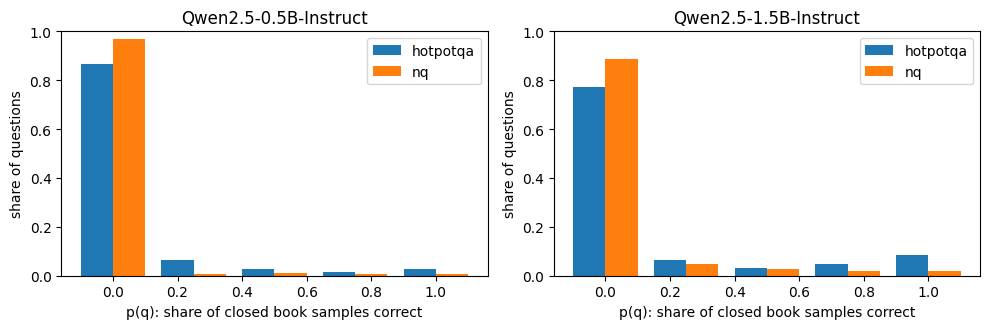

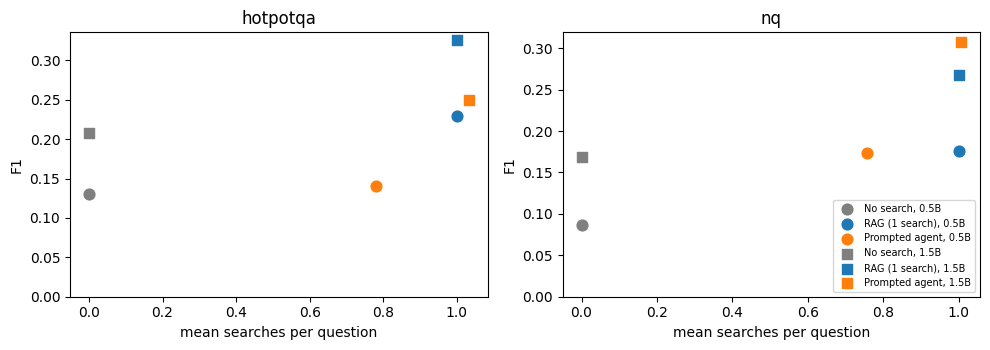


Qwen2.5-0.5B-Instruct: 6.5% of probe questions have 0 < p(q) < 1 -> NO-GO: rebalance toward NQ/PopQA and raise K to 8
Saved /content/drive/MyDrive/search_or_think/outputs/interim_summary.json and figures in /content/drive/MyDrive/search_or_think/outputs/figures.
{
 "bm25_recall": {
  "queries_per_sec": 62.80845641840326,
  "hotpotqa_any_gold@3": 0.742,
  "hotpotqa_both_gold@3": 0.132,
  "hotpotqa_any_gold@10": 0.804,
  "hotpotqa_both_gold@10": 0.32,
  "nq_answer_in_top3": 0.416,
  "nq_answer_in_top10": 0.568
 },
 "pq_distribution": {
  "Qwen2.5-0.5B-Instruct": {
   "hotpotqa": {
    "n": 500,
    "hist": {
     "0.0": 434,
     "0.25": 32,
     "0.5": 13,
     "0.75": 8,
     "1.0": 13
    },
    "p0": 0.868,
    "mid": 0.106,
    "p1": 0.026
   },
   "nq": {
    "n": 500,
    "hist": {
     "0.0": 484,
     "0.25": 3,
     "0.5": 6,
     "0.75": 3,
     "1.0": 4
    },
    "p0": 0.968,
    "mid": 0.024,
    "p1": 0.008
   }
  },
  "Qwen2.5-1.5B-Instruct": {
   "hotpotqa": {
    "n": 

In [ ]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd

from sot.analysis import boundary_signal, load_jsonl, p_by_id, p_distribution, qor, sor, summarize

MODELS = ["Qwen2.5-0.5B-Instruct", "Qwen2.5-1.5B-Instruct"]
TRAIN_MODEL = "Qwen2.5-0.5B-Instruct"  # the model RL will train
GO_MIN_MID = 0.20  # go if >= 20% of probe questions have 0 < p(q) < 1 for the training model
METHODS = {"no_search": "No search", "rag": "RAG (1 search)", "agent": "Prompted agent"}
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)

recs = {r["id"]: r for ds in ("hotpotqa", "nq") for sp in ("test", "probe")
        for r in load_jsonl(f"{DATA}/{ds}_{sp}.jsonl")}
acc, pdist, extra, timing = [], {}, {}, {}
for m in MODELS:
    d = f"{OUT}/{m}"
    if not os.path.exists(f"{d}/timings.json"):
        print("no completed run for", m)
        continue
    run = lambda t: load_jsonl(f"{d}/{t}.jsonl")  # noqa: E731
    for t, label in METHODS.items():
        acc += [{"model": m, "method": label, "dataset": ds, **s} for ds, s in summarize(run(t)).items()]
    closed = run("closed_sampled")
    pmap = p_by_id(closed)
    pdist[m] = p_distribution(pmap, [r for r in recs.values() if r["split"] == "probe" and r["id"] in pmap])
    agent = run("agent")
    extra[m] = {"qor": qor(agent, pmap), "sor": sor(agent, recs),
                "signal": boundary_signal([r for r in closed if r["split"] == "probe"], run("agent_sampled"))}
    timing[m] = json.load(open(f"{d}/timings.json"))["minutes"]

acc = pd.DataFrame(acc)
table = acc.pivot_table(index=["model", "method"], columns="dataset", values=["em", "f1", "searches"]).round(3)
display(table)  # noqa: F821

# Figure 1: p(q) distribution on the training probe (decides whether Soft-SAAS has room to differ from SAAS)
fig, axes = plt.subplots(1, len(pdist), figsize=(5 * len(pdist), 3.4), squeeze=False)
for ax, (m, dist) in zip(axes[0], pdist.items()):
    for j, (ds, v) in enumerate(dist.items()):
        xs = sorted(v["hist"])
        ax.bar([x + (j - 0.5) * 0.1 for x in xs], [v["hist"][x] / v["n"] for x in xs], width=0.1, label=ds)
    ax.set(title=m, xlabel="p(q): share of closed book samples correct", ylabel="share of questions", ylim=(0, 1))
    ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG}/pq_distribution.png", dpi=200)
plt.show()

# Figure 2: accuracy vs search count (the frontier figure; RL methods get added here later)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
colors = dict(zip(METHODS.values(), ["tab:gray", "tab:blue", "tab:orange"]))
for ax, ds in zip(axes, ["hotpotqa", "nq"]):
    for _, r in acc[acc.dataset == ds].iterrows():
        ax.scatter(r.searches, r.f1, color=colors[r.method], marker="o" if "0.5B" in r.model else "s", s=60,
                   label=f"{r.method}, {r.model.split('-')[1]}")
    ax.set(title=ds, xlabel="mean searches per question", ylabel="F1", ylim=(0, None))
axes[1].legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG}/accuracy_vs_searches.png", dpi=200)
plt.show()

# Go / no-go on the training model
mids = pdist.get(TRAIN_MODEL, {})
n_all = sum(v["n"] for v in mids.values())
mid_share = sum(v["mid"] * v["n"] for v in mids.values()) / n_all if n_all else float("nan")
verdict = "GO" if mid_share >= GO_MIN_MID else "NO-GO: rebalance toward NQ/PopQA and raise K to 8"
print(f"\n{TRAIN_MODEL}: {mid_share:.1%} of probe questions have 0 < p(q) < 1 -> {verdict}")

summary = {"bm25_recall": json.load(open(f"{OUT}/bm25_recall.json")) if os.path.exists(f"{OUT}/bm25_recall.json") else None,
           "accuracy": acc.round(4).to_dict(orient="records"), "pq_distribution": pdist, "over_search": extra,
           "go_no_go": {"model": TRAIN_MODEL, "mid_share": mid_share, "verdict": verdict}, "minutes": timing}
with open(f"{OUT}/interim_summary.json", "w") as f:
    json.dump(summary, f, indent=1, default=str)
print(f"Saved {OUT}/interim_summary.json and figures in {FIG}.")
print(json.dumps({k: v for k, v in summary.items() if k != "accuracy"}, indent=1, default=str))
print(table.to_string())


## 9. Stop paying for the GPU
Run this once the summary is saved.

In [ ]:
from google.colab import runtime
runtime.unassign()